Na poprzednich zajęciach:
- **tokenizacja** – podział tekstu na słowa / tokeny,
- **spaCy Matcher** – znajdowanie wzorców na podstawie części mowy i cech morfologicznych.

# Wektory słów


## Tokenizacja a wektory słów

Tokenizacja -> Podziel tekst na kawałki (ID ze słownika)

Embedding -> Przedstaw każde słowo w postaci liczb, aby algorytm mógł z nim dalej pracować

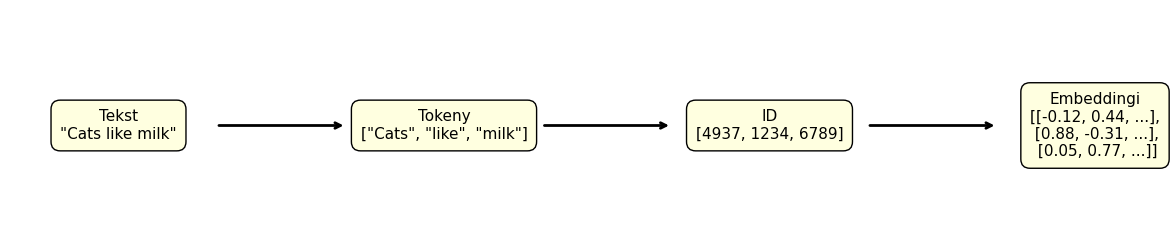

Komputer nie „rozumie” tekstu, tylko operuje na liczbach.
Zatem każde słowo (np. „król”, „kot”, „miłość”) trzeba jakoś zamienić na liczby, żeby można było nim manipulować w modelu.

Najprostszy pomysł — **one-hot encoding**


```
słownik = [kot, król, królowa]
"król" → [0, 1, 0]
```

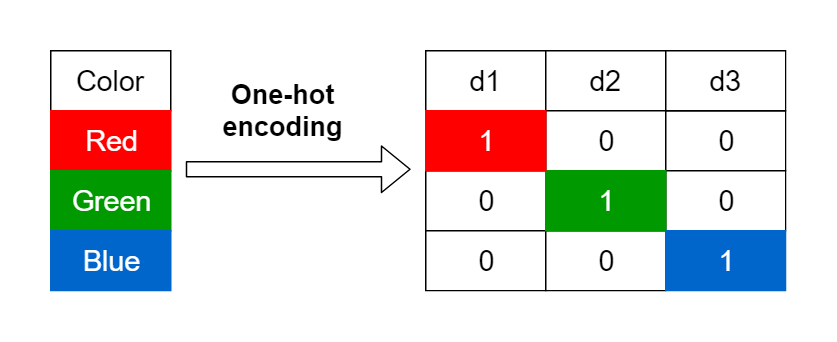



Dlaczego one-hot encoding jest problematyczny?

❌  Bardzo duży wymiar - Jeśli mamy słownik np. 100 000 słów, każdy wektor ma długość 100 000 — to ogromne marnotrawstwo pamięci.

❌ Brak informacji o znaczeniu - Wszystkie wektory są od siebie tak samo odległe — np. “kot” i “pies” są tak samo różne jak “kot” i “samolot”.
Nie ma żadnego pojęcia o podobieństwie semantycznym (znaczeniowym).

❌ Brak możliwości uogólniania - Model nie może „zrozumieć”, że pewne słowa mają podobne znaczenie — każde słowo jest całkowicie niezależne.

```
słownik = [kot, król, królowa]
"kot" → [1, 0, 0]
"król" → [0, 1, 0]
"królowa" → [0, 0, 1]
```

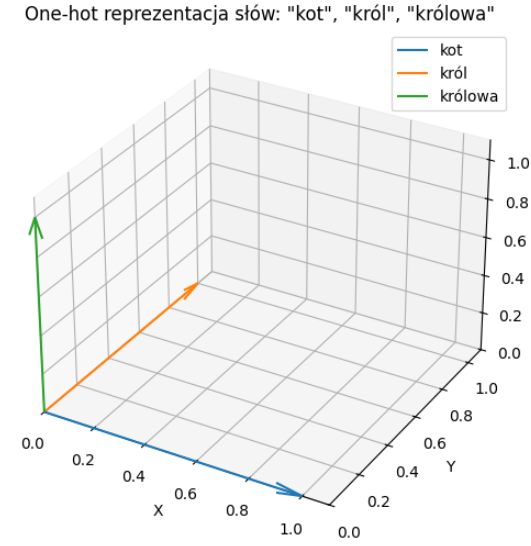

Widzimy, że każdy wektor idzie w swoją stronę, każdy jest tak samo odległy od siebie (90 stopni). Żadne dwa nie są do siebie bliżej ani dalej — odległość między każdym z nich jest taka sama.

W naszym przykładzie: kot, król i królowa są tak samo podobni i różni = nie ma wartości semantycznej.

## Embedingi
Embeddingi rozwiązują ten problem. W embeddingach uczymy model, żeby słowa, które występują w podobnych kontekstach, miały **podobne wektory**.

Dwa wektory są podobne, kiedy wskazują w podobnym kierunku w przestrzeni wielowymiarowej.
Czyli: jeśli narysujesz te wektory jako strzałki zaczynające się w tym samym punkcie (np. w punkcie (0,0,0)) to mają **mały kąt między sobą**.

Przykład:
```
"king" → [0.25, 0.88, -0.12, 0.40, ...]
"queen" → [0.22, 0.90, -0.10, 0.45, ...]
"cat" → [-0.70, 0.11, 0.45, 0.20, ...]
```


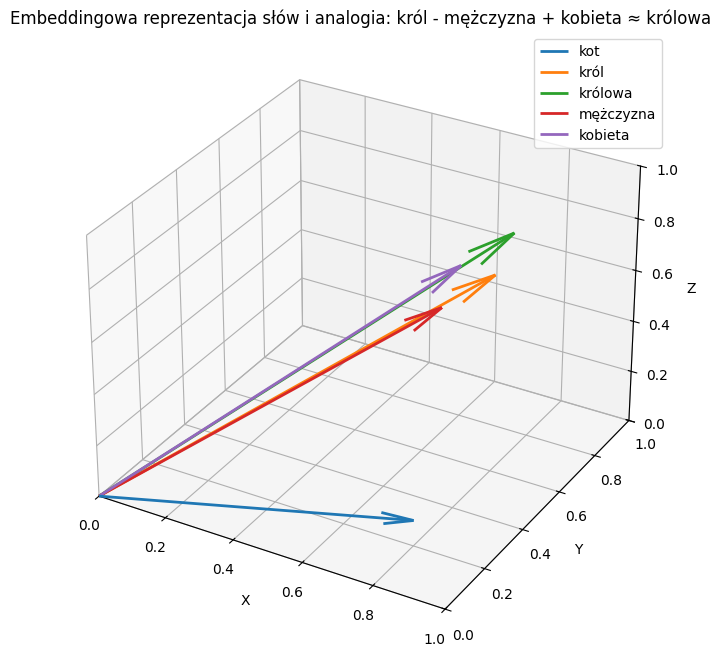


```
król − mężczyzna + kobieta ≈ królowa
```



Teraz punkty w przestrzeni układają się tak, że słowa o podobnym znaczeniu są blisko siebie.
To jest właśnie **semantyczne podobieństwo** —
podobieństwo w sensie znaczenia, a nie liter czy indeksów w tabeli.

## Cosinusowe podobieństwo — jak mierzymy „bliskość znaczeń”

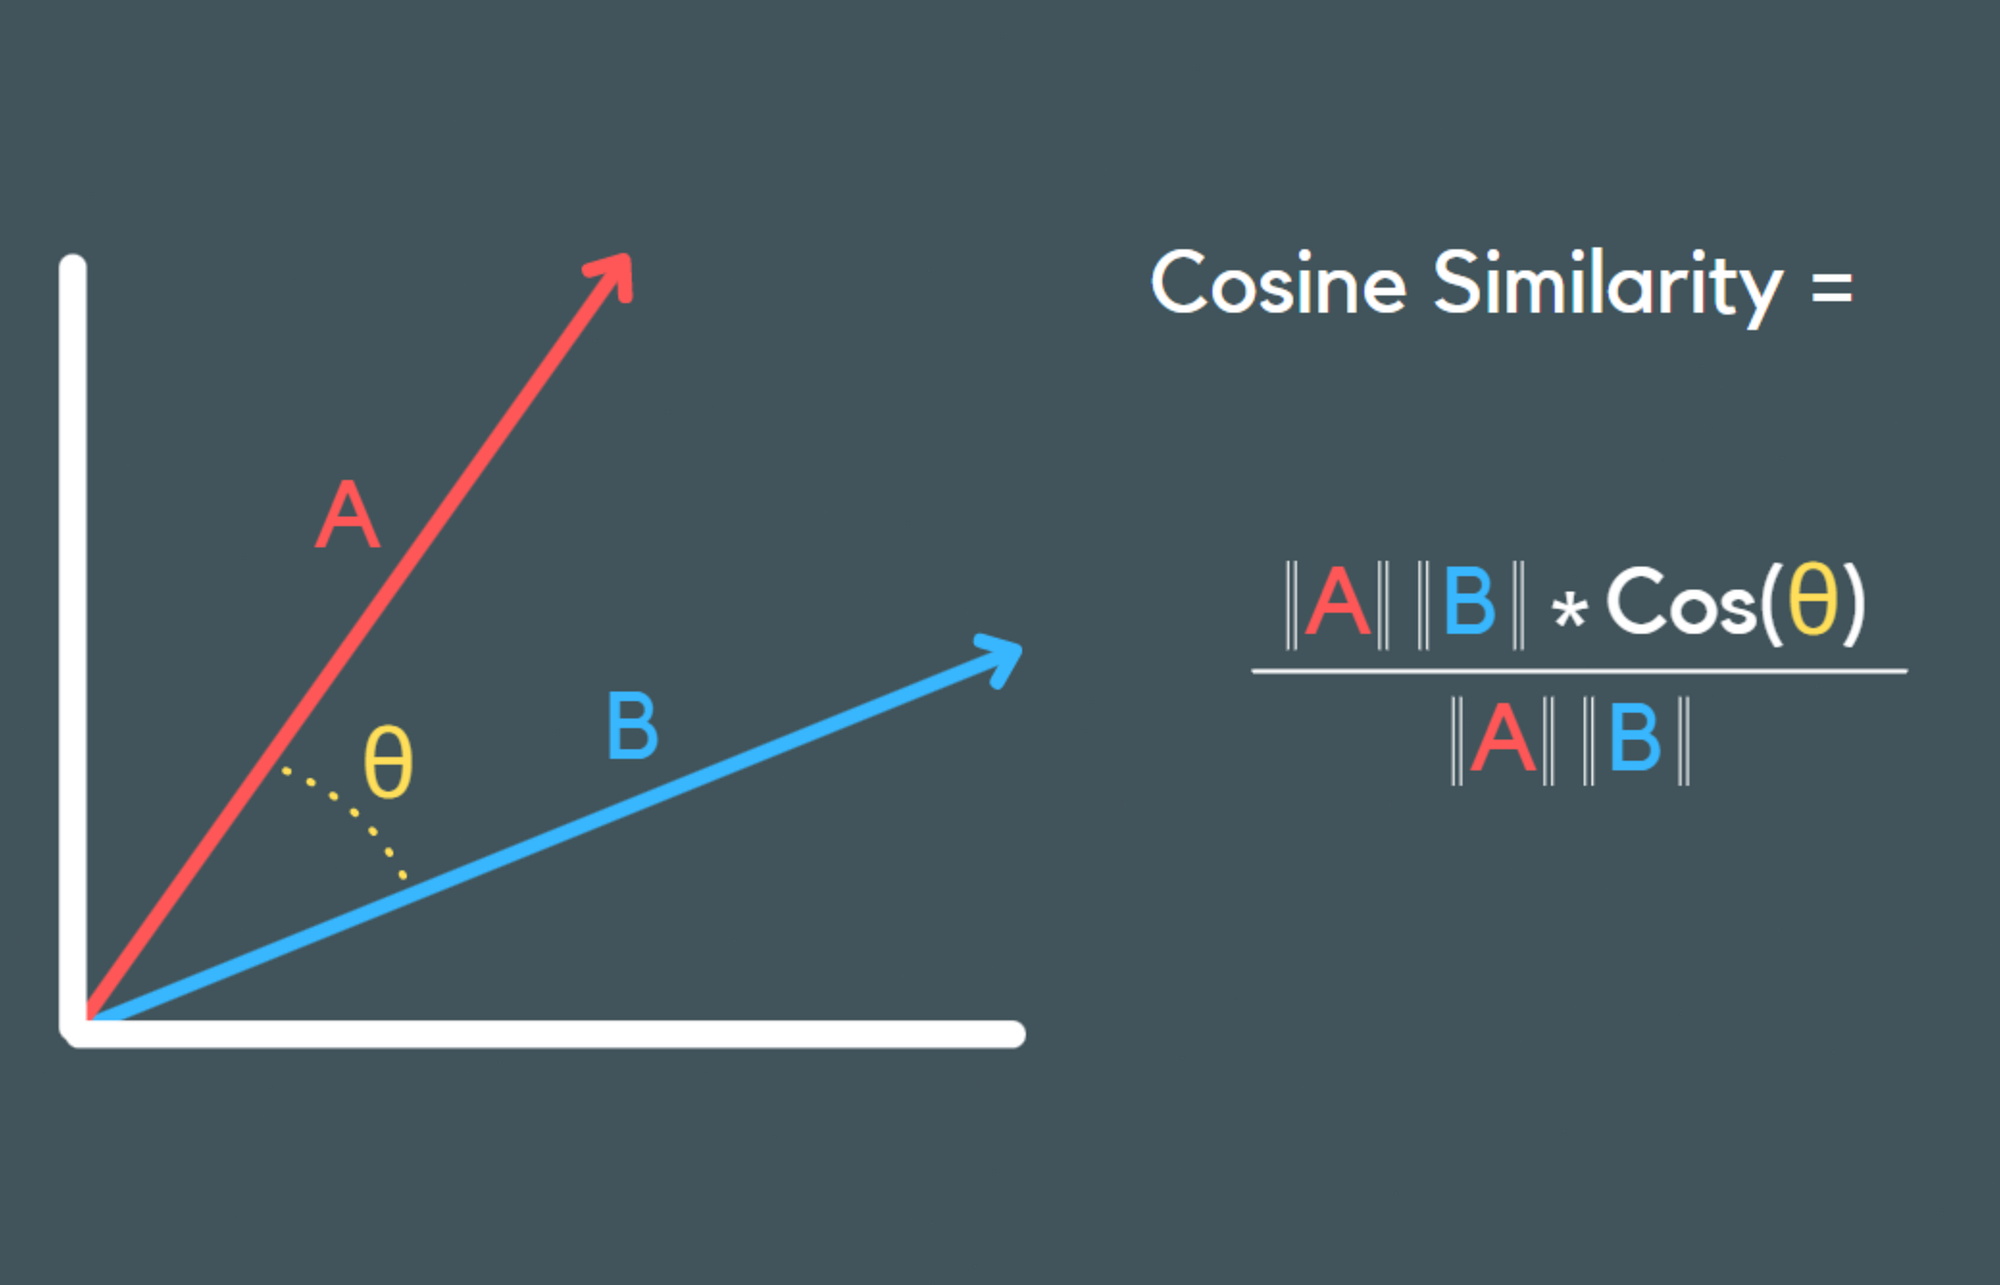

Cosinusowe podobieństwo to sposób na sprawdzenie, czy dwa wektory są „w tym samym kierunku”:

*  1 → bardzo podobne (np. „kot” i „pies”)
*  0 → brak podobieństwa (np. „kot” i „okno”)
*  -1 → całkowite przeciwieństwo

Ważne: Patrzymy nie na długość wektorów, tylko na kąt między nimi.
Dwa wektory, które „patrzą” w tym samym kierunku, oznaczają słowa o podobnym znaczeniu.

Skąd się biorą te wektory?

Z treningu modelu językowego (np. Word2Vec, GloVe, FastText, BERT).
Model uczy się na dużych korpusach tekstu, obserwując konteksty słów.


Efekt:

„king” i „queen” często występują w podobnych zdaniach (np. royal palace, throne, reign) → mają podobne wektory.

„dog” i „cat” też → inna grupa semantyczna.

## Trochę praktyki

Zaczniemy od zapoznania się z bibloteką **gensim**
Jej nazwa pochodzi od "GENerate SIMilar" — bo jej głównym celem jest znajdowanie podobieństwa między dokumentami lub słowami.

Użyjemy klasy **KeyedVectors** - to strukturą danych  w gensim, która przechowuje wektory słów (embeddingi) wytrenowane dowolnym modelem. Czyli po prostu taki kontener do pracy z wektorami - niezależnie od tego, jak one zostały wytrenowane.

In [1]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 1.4 MB/s  0:00:19m0:00:0100:010m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 2.8 MB/s  0:00:12m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [gensim]2m1/2 [gensim]


In [2]:
import gensim
from gensim.models import KeyedVectors

weźmiemy sobie polskie pre-trenowane wektory: http://dsmodels.nlp.ipipan.waw.pl
pobieramy plik:

In [3]:
!wget http://dsmodels.nlp.ipipan.waw.pl/dsmodels/nkjp+wiki-forms-restricted-300-skipg-ns.txt.gz --no-check-certificate

--2026-10-16 10:55:09--  http://dsmodels.nlp.ipipan.waw.pl/dsmodels/nkjp+wiki-forms-restricted-300-skipg-ns.txt.gz
Resolving dsmodels.nlp.ipipan.waw.pl (dsmodels.nlp.ipipan.waw.pl)... 213.135.36.94
Connecting to dsmodels.nlp.ipipan.waw.pl (dsmodels.nlp.ipipan.waw.pl)|213.135.36.94|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://dsmodels.nlp.ipipan.waw.pl/dsmodels/nkjp+wiki-forms-restricted-300-skipg-ns.txt.gz [following]
--2026-10-16 10:55:09--  https://dsmodels.nlp.ipipan.waw.pl/dsmodels/nkjp+wiki-forms-restricted-300-skipg-ns.txt.gz
Connecting to dsmodels.nlp.ipipan.waw.pl (dsmodels.nlp.ipipan.waw.pl)|213.135.36.94|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2152612134 (2.0G) [application/octet-stream]
Saving to: ‘nkjp+wiki-forms-restricted-300-skipg-ns.txt.gz’

nkjp+wiki-forms-res 100%[===================>]   2.00G  3.06MB/s    in 19m 43s 

2026-10-16 11:14:39 (1.74 MB/s) - ‘nkjp+wiki-forms-restricted-30

Rozpakowujemy dane

In [4]:
!gzip -d "nkjp+wiki-forms-restricted-300-skipg-ns.txt.gz"

Badamy format pliku

In [5]:
!head -n 100 nkjp+wiki-forms-restricted-300-skipg-ns.txt
#Pierwsza linia - lość słów (1982479), rozmiar wektora(300)
#Każda kolejna linia - słowo, liczby reperezentujące wektor

1982479 300
jest -0.127787 0.008677 -0.404733 0.076550 -0.071382 -0.005960 -0.357351 -0.104665 0.344031 0.607296 0.304090 0.205259 0.202547 0.078905 -0.004999 -0.330064 0.103000 -0.036481 -0.091464 -0.092434 0.534286 0.056750 0.283086 -0.317479 -0.321016 -0.089463 0.063402 0.131147 0.078863 -0.263648 -0.137772 0.073504 -0.172304 0.093762 -0.073707 0.231672 -0.086635 0.171582 -0.336881 -0.276816 -0.348653 -0.227359 0.129980 0.021752 -0.200256 -0.107671 0.060041 0.119810 0.296956 0.075233 -0.278887 0.000536 0.164630 0.017116 0.009912 -0.001985 -0.235770 0.046479 -0.080487 0.280712 0.029184 -0.103512 0.242497 0.312486 0.311952 0.335492 -0.014899 -0.106173 -0.336280 -0.103677 0.054153 -0.321120 0.005779 0.140240 -0.008623 -0.029031 -0.150106 0.396968 -0.117699 0.159344 -0.249547 0.107071 0.300655 -0.212291 -0.312293 -0.134519 0.204264 0.312330 0.329351 0.139512 0.160484 -0.135964 -0.278442 0.143398 0.278890 0.019378 0.042938 -0.068675 0.066873 0.297572 0.151743 -0.024631 -0.013845 0.260533

(to może chwilę zająć)

In [6]:
#Ładowanie wektorów z pliku do naszego KeyedVectors
wv = KeyedVectors.load_word2vec_format('nkjp+wiki-forms-restricted-300-skipg-ns.txt')

In [7]:
wv.key_to_index.keys()
wv['dom']

array([-0.39294 , -0.156333,  0.017816, -0.208752,  0.442839, -0.389071,
       -0.22354 ,  0.119761,  0.201861,  0.136966,  0.005829, -0.036992,
       -0.075693, -0.424958,  0.031507, -0.214998, -0.11862 , -0.059799,
       -0.150971, -0.176567,  0.444136,  0.18925 ,  0.241265, -0.248733,
       -0.176206,  0.579075,  0.031083,  0.253453,  0.101754,  0.144021,
       -0.169662, -0.005122,  0.056225,  0.078038, -0.557848, -0.365922,
       -0.108863,  0.322074, -0.178232,  0.289982, -0.205699,  0.001991,
        0.001029, -0.074944,  0.173145,  0.044346, -0.032673, -0.060124,
        0.152098, -0.293121, -0.280878,  0.377744,  0.402627, -0.737609,
        0.020663, -0.01301 ,  0.134813, -0.052369,  0.046645, -0.024955,
        0.100392, -0.295437, -0.418354,  0.396864,  0.232666,  0.022819,
       -0.018474,  0.385309, -0.084371,  0.269105,  0.149824, -0.161652,
        0.282115,  0.177849, -0.241524, -0.240634, -0.111456,  0.070668,
       -0.216499, -0.139156, -0.576622, -0.136423, 

 Znajdziemy najbardziej podobne słowo do słowa kobieta.

In [8]:
wv.most_similar('kobieta')

[('mężczyzna', 0.7043285369873047),
 ('dziewczyna', 0.6813511252403259),
 ('ciężarna', 0.612939715385437),
 ('dziewczynka', 0.6094770431518555),
 ('50-letnia', 0.5805984139442444),
 ('młoda', 0.5788260102272034),
 ('40-letnia', 0.5631040930747986),
 ('kobietą', 0.5611501336097717),
 ('dama', 0.5526077747344971),
 ('mężczyzną', 0.5519220232963562)]

Znajdź najbardziej podobne słowo do słowa "kobieta", które nie jest podobne do słowa "mężczyzna"

In [9]:
wv.most_similar(positive=['kobieta'], negative=['mężczyzna'])

[('Teresa', 0.3597542345523834),
 ('Irlandka', 0.35389503836631775),
 ('Barbara', 0.33941537141799927),
 ('Helena', 0.33837634325027466),
 ('Eleonora', 0.32829549908638),
 ('mianowana', 0.3252837657928467),
 ('Maryse', 0.32269802689552307),
 ('Emmanuella', 0.32241636514663696),
 ('czarnoskóra', 0.3224010169506073),
 ('Izabela', 0.3222866654396057)]

W grupie "pies kot żubr budyń" znajdź słowo, które nie pasuje.

In [10]:
wv.doesnt_match(['pies', 'kot', 'żubr', 'budyń'])

'budyń'

zbadaj podobieństwo między kotem a psem

In [11]:
wv.similarity('kot', 'pies')

np.float32(0.6970217)

Teraz zajmiemy się podobieństwami pomiędzy zdaniami

Word mover distance to minimalna suma odległości, jaką trzeba „pokonać”, aby słowa z jednego zdania pokryły znaczeniowo słowa z drugiego zdania.

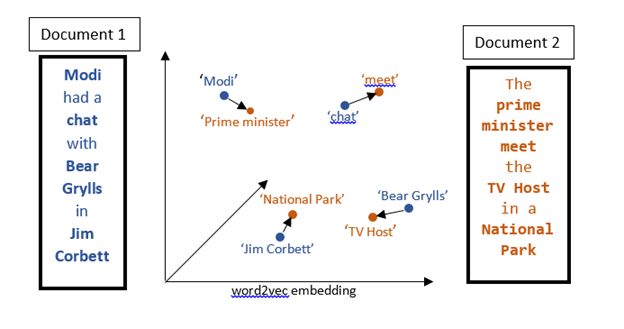

In [12]:
!pip install POT #Po tej instalacji gensim może szybciej i dokładniej liczyć wmdistance

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.9/32.9 MB 15.4 MB/s  0:00:02 eta 0:00:01


In [13]:
sentence_1 = 'Byłem dzisiaj w kinie'.lower().split()
sentence_2 = 'Poszłam wczoraj do teatru'.lower().split()

In [14]:
wv.wmdistance(sentence_1, sentence_2)


1.176677407878612

WMD nie jest ograniczone do 0-1, ale przy normalizacji embeddingów zwykle wartości mieszczą się w 0-4 dla krótkich zdań.

wynik ~1.25 sugeruje, że zdania są umiarkowanie podobne semantycznie.

Dla porównania:

* Dwa identyczne zdania → WMD ≈ 0

* Zupełnie różne zdania → WMD > 2.5-3

## Flair

Flair to biblioteka NLP od Zalando Research (Python)

**Główna idea:**

* Klasyczne embeddingi (Word2Vec, GloVe, FastText) dają stały wektor dla każdego słowa, niezależnie od kontekstu:

    *"bank"* w *"river bank"* i *"money bank"* → ten sam wektor.

* Flair tworzy kontekstowe embeddingi(wektor słowa zależy od jego zdania / kontekstu)

    więc "*bank*" w "*river bank*" będzie inny niż w "*money bank*".

Flair uczy się tego przez modele LSTM działające w dwóch kierunkach (forward i backward).

In [15]:
!pip install flair

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 772.6 kB/s  0:00:01a 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached transformers-4.57.6-py3-none-any.whl.metadata (43 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached tokenizers-0.22.2-cp39-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (7.3 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 836.4 kB/s  0:00:01 eta 0:00:01
Using cached transformers-4.57.6-py3-none-

In [16]:
from flair.embeddings import FlairEmbeddings, StackedEmbeddings
from flair.data import Sentence

/home/evilree/PJN/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [17]:
embeddings = FlairEmbeddings('news-forward')

#tworzymy objekty Sentence
s1 = Sentence("How does it feel to be a scribe?")
s2 = Sentence("There is no such thing as simply good or bad")
sentences = [s1, s2]


# Obliczamy embeddingi(zanurzamy słowa)
embeddings.embed(sentences)

for sentence in sentences: #Zanurzone zdania nadal są obiektem Sentence
  print(sentence)

2026-10-16 11:55:52,646 https://flair.informatik.hu-berlin.de/resources/embeddings/flair/news-forward-0.4.1.pt not found in cache, downloading to /tmp/tmpqii98b8g


100%|██████████| 69.7M/69.7M [00:06<00:00, 10.8MB/s]

2026-10-16 11:55:59,672 copying /tmp/tmpqii98b8g to cache at /home/evilree/.flair/embeddings/news-forward-0.4.1.pt
2026-10-16 11:55:59,741 removing temp file /tmp/tmpqii98b8g


Sentence[9]: "How does it feel to be a scribe?"
Sentence[10]: "There is no such thing as simply good or bad"


In [18]:
#dostajemy embeddingi poszczególnych słów
for sentence in sentences:
  for token in sentence:
    print(token.embedding)
#embeddingi są tensorami

tensor([-0.0011, -0.0021,  0.0038,  ..., -0.0004,  0.0099,  0.0547])
tensor([-0.0016, -0.0260,  0.0388,  ...,  0.0031, -0.0070,  0.0025])
tensor([0.0174, 0.0181, 0.0148,  ..., 0.0051, 0.0051, 0.0130])
tensor([ 0.0001,  0.0128,  0.0476,  ..., -0.0084, -0.0023,  0.0106])
tensor([-2.1672e-03,  8.3753e-05,  2.5102e-02,  ..., -2.8347e-04,
        -1.2090e-02,  2.9513e-02])
tensor([-0.0032,  0.0020,  0.0280,  ...,  0.0004, -0.0017, -0.0106])
tensor([ 5.3283e-03,  3.8049e-05, -2.2042e-02,  ..., -4.1646e-04,
         1.9279e-02, -1.2351e-02])
tensor([-1.0594e-03,  4.8670e-05,  2.1462e-02,  ..., -1.1294e-05,
        -4.3308e-03,  3.1280e-03])
tensor([ 8.7317e-04,  3.7862e-06, -4.6351e-04,  ..., -1.4222e-04,
         5.4708e-03,  3.0888e-03])
tensor([-0.0012, -0.0002, -0.1499,  ...,  0.0024,  0.0017,  0.1648])
tensor([ 0.0078, -0.0047,  0.0564,  ..., -0.0012,  0.0325,  0.0035])
tensor([ 5.8074e-02, -7.9190e-05,  9.8895e-02,  ..., -2.7518e-03,
         8.8326e-04,  2.6957e-02])
tensor([-0.0004, -

In [19]:
import numpy as np

In [20]:
for sentence in sentences:
  for token in sentence:
    print(np.array(token.embedding))

[-0.00108573 -0.00213397  0.00377833 ... -0.00035715  0.0099433
  0.05467612]
[-0.00163258 -0.02604993  0.03880594 ...  0.00308893 -0.00699765
  0.00248321]
[0.01740974 0.01807804 0.0147752  ... 0.00507008 0.00508688 0.01302868]
[ 0.00013419  0.01282798  0.04760626 ... -0.00837356 -0.00231261
  0.01057426]
[-2.1671702e-03  8.3752588e-05  2.5102206e-02 ... -2.8347093e-04
 -1.2090425e-02  2.9513163e-02]
[-0.00319913  0.00195263  0.02804686 ...  0.00040722 -0.00174229
 -0.01062463]
[ 5.32832043e-03  3.80494457e-05 -2.20420863e-02 ... -4.16457391e-04
  1.92785766e-02 -1.23509625e-02]
[-1.0594028e-03  4.8669703e-05  2.1461956e-02 ... -1.1294257e-05
 -4.3307757e-03  3.1279572e-03]
[ 8.7317190e-04  3.7861769e-06 -4.6351264e-04 ... -1.4222013e-04
  5.4707765e-03  3.0888412e-03]
[-0.00118427 -0.00018427 -0.14988413 ...  0.00244023  0.00166776
  0.16482687]
[ 0.00780449 -0.00474085  0.056434   ... -0.00120921  0.03250852
  0.00350805]
[ 5.8073573e-02 -7.9189987e-05  9.8894574e-02 ... -2.7517818e

/tmp/ipykernel_5726/932037997.py:3: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  print(np.array(token.embedding))


Embeddingi dla zdań

In [21]:
from flair.embeddings import DocumentPoolEmbeddings

In [22]:
sentence_embeddings = DocumentPoolEmbeddings([FlairEmbeddings('news-forward')])

In [23]:
sentence_embeddings.embed(sentences)

In [24]:
for sentence in sentences:
  print(sentence.embedding)

tensor([ 0.0016,  0.0005,  0.0175,  ..., -0.0001,  0.0014,  0.0104])
tensor([ 0.0073, -0.0008,  0.0052,  ..., -0.0007, -0.0124,  0.0289])


# Zadania

###Zadanie1

Załaduj polski model kontekstowych embeddingów Flair:

In [26]:
embeddings = FlairEmbeddings('pl-forward')

In [27]:
s1 = Sentence("Zamek w Malborku jest bardzo stary.")
s2 = Sentence("Suwak w kurtce to zamek błyskawiczny")
s3 = Sentence("Sprawdź, czy zamek w drzwiach działa")
sentences = [s1, s2, s3]

Oblicz embeddingi dla wszystkich zdań:

In [28]:
embeddings.embed(sentences)

[Sentence[7]: "Zamek w Malborku jest bardzo stary.",
 Sentence[6]: "Suwak w kurtce to zamek błyskawiczny",
 Sentence[7]: "Sprawdź, czy zamek w drzwiach działa"]

Wypisz każde zdanie i dla słowa "zamek", wypisz pierwsze 5 wymiarów embeddingu:

In [29]:
for sentence in sentences:
    print(sentence)
    for token in sentence:
        if token.text.lower() == "zamek":
            print("zamek:", token.embedding[:5])

Sentence[7]: "Zamek w Malborku jest bardzo stary."
zamek: tensor([-5.4509e-03, -2.1590e-02,  4.5458e-05, -1.7073e-04, -4.3133e-04])
Sentence[6]: "Suwak w kurtce to zamek błyskawiczny"
zamek: tensor([-0.0043, -0.0131,  0.0004, -0.0001, -0.0004])
Sentence[7]: "Sprawdź, czy zamek w drzwiach działa"
zamek: tensor([-4.3021e-03, -2.1082e-02,  7.7413e-04, -6.9931e-05, -3.6798e-04])


Czy embeddingi są różne w zależności od znaczenia słowa?

Odpowiedź: Tak

###Zadanie 2

Stwórz bota z bazą przykładownych pytań i odpowiedzi, zwracającego odpowiedź na zapytanie na podstawie podobieństwa (WMD albo flair document embeddings) pomiędzy zapytniem użytownika a pytaniami w swojej bazie

Przykład:

Zbiór pytań i odpowiedzi :

```
[
  {"q1" : "a1"},
  {"q2" : "a2"},
  {"q3" : "a3"},
  ...
  {"qn" : "an"},
]
```
Wektoryzujemy pytania:

```
  {"q1_vecotorized" : "a1"},
  {"q2_vecotorized" : "a2"},
  {"q3_vecotorized" : "a3"},
  ...
  {"qn_vecotorized" : "an"},
```
Dla pytania użytkownia pytania q_user wektoryzujemy je i liczmy podobieństwo z pytaniami w bazie


```
sim("q_user_vectorized","q1_vecotorized"), sim("q_user_vectorized","q2_vecotorized"), ... ("q_user_vectorized""qn_vecotorized")

```
Zwracamy odpowiedź do pytania z bazy najbardziej podobnego do pytania użytkownika
$$
argmax(sim(q_{user}vectorized,q_{i}vecotorized))
$$

Do liczenia podobnieństma można użyć np https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.cosine.html ale wtedy robimy argmin bo
$$
cosine\ distance = 1 - cosine\ similarity
$$




In [31]:
qa = [
  {"q": "Jaka jest stolica Polski?", "a": "Stolicą Polski jest Warszawa."},
  {"q": "Ile nóg ma pająk?", "a": "Pająk ma osiem nóg."},
  {"q": "Kto napisał Pana Tadeusza?", "a": "Pana Tadeusza napisał Adam Mickiewicz."},
  {"q": "Jak zrobić herbatę?", "a": "Zagotuj wodę, zalej torebkę herbaty i odczekaj 3-5 minut."},
  {"q": "Jaka będzie jutro pogoda?", "a": "Nie mam dostępu do prognozy pogody, sprawdź serwis meteo."},
  {"q": "Ile kosztuje bilet do kina?", "a": "Bilet do kina kosztuje zwykle od 20 do 35 zł."},
  {"q": "Gdzie leży Kraków?", "a": "Kraków leży w południowej Polsce, nad Wisłą."},
  {"q": "Jaki ser jest najlepszy do pizzy?", "a": "Do pizzy najlepsza jest mozzarella."},
]

In [35]:
# importy
from scipy.spatial.distance import cosine
from flair.embeddings import FlairEmbeddings, DocumentPoolEmbeddings
from flair.data import Sentence

document_embeddings = DocumentPoolEmbeddings([FlairEmbeddings('pl-forward')])

def vectorize(text):
  sentence = Sentence(text)
  document_embeddings.embed(sentence)
  return sentence.embedding.detach().numpy()

qa_vectorized = [{"q_vec": vectorize(item["q"]), "q": item["q"], "a": item["a"]} for item in qa]

def bot(user_question):
  user_vec = vectorize(user_question)

  similarities = [calculate_similarity(user_vec, item["q_vec"]) for item in qa_vectorized]
  best_index = similarities.index(max(similarities))
  best = qa_vectorized[best_index]

  print(f"Pytanie użytkownika: {user_question}")
  print(f"Najbardziej podobne pytanie z bazy danych: {best['q']}")
  print(f"Odpowiedź: {best['a']}")

def calculate_similarity(vec1, vec2):
    return 1 - cosine(vec1, vec2)

In [36]:
bot("Jakie miasto jest stolicą naszego kraju?")
print()
bot("Kto jest autorem Pana Tadeusza?")
print()
bot("Jaki ser polecasz na pizzę?")

Pytanie użytkownika: Jakie miasto jest stolicą naszego kraju?
Najbardziej podobne pytanie z bazy danych: Jaka jest stolica Polski?
Odpowiedź: Stolicą Polski jest Warszawa.

Pytanie użytkownika: Kto jest autorem Pana Tadeusza?
Najbardziej podobne pytanie z bazy danych: Kto napisał Pana Tadeusza?
Odpowiedź: Pana Tadeusza napisał Adam Mickiewicz.

Pytanie użytkownika: Jaki ser polecasz na pizzę?
Najbardziej podobne pytanie z bazy danych: Jaki ser jest najlepszy do pizzy?
Odpowiedź: Do pizzy najlepsza jest mozzarella.
